## Data Science Project:

An Information Retrieval Engine


This notebook was designed on Google Colab. We recommend viewing it via Colab
to avoid any display issues with section titles and cell outputs.

#**Phase 1: Retrieval Basics:**


##**1. Data Exploration, Statistics, and Preparation**




**Importer le dataset de Kaggle**



In [ ]:
# Install the Kaggle API
!pip install -q kaggle

In [ ]:
# Import required libraries for data handling, text processing, and visualization

import json              # To read and write JSON files
import os                # To interact with the operating system (files, directories)
import sys               # To access system-specific parameters and functions
import regex as re       # Advanced regular expressions for text processing
import zipfile           # To extract and handle ZIP files
import pandas as pd      # Data manipulation and analysis (DataFrames)
import matplotlib.pyplot as plt  # Data visualization (plots and charts)
import numpy as np       # Numerical computing (arrays, mathematical operations)
from collections import Counter, defaultdict  # Counting and dictionary utilities
import statistics        # Basic statistical functions (mean, median, etc.)
import seaborn as sns    # Statistical data visualization built on Matplotlib

In [ ]:
# Kaggle credentials are read from environment variables (never commit your API key)
kaggle_token = {
    "username": os.environ.get("KAGGLE_USERNAME", "YOUR_KAGGLE_USERNAME"),
    "key": os.environ.get("KAGGLE_KEY", "YOUR_KAGGLE_KEY")
}

# Create the .kaggle directory (if it does not already exist)
os.makedirs("/root/.kaggle", exist_ok=True)

# Write the kaggle.json configuration file
with open("/root/.kaggle/kaggle.json", "w") as f:
    json.dump(kaggle_token, f)

# Set the correct file permissions (read/write for the owner only)
!chmod 600 /root/.kaggle/kaggle.json

print("Kaggle configured successfully ✅")

Kaggle configured successfully ✅


In [ ]:
# Download the competition dataset from Kaggle
!kaggle competitions download -c retrieval-engine-competition

# Unzip the downloaded dataset (overwrite existing files if needed)
!unzip -o retrieval-engine-competition.zip

  0% 0.00/82.8M [00:00<?, ?B/s]
100% 82.8M/82.8M [00:00<00:00, 1.56GB/s]
Archive:  retrieval-engine-competition.zip
  inflating: docs.json               
  inflating: qgts_train.json         
  inflating: queries_test.json       
  inflating: queries_train.json      
  inflating: submission.csv          


In [ ]:
import json

# Load the documents dataset
with open("docs.json", "r") as f:
    documents = json.load(f)

# Load training queries
with open("queries_train.json", "r") as f:
    train_queries = json.load(f)

# Load relevance judgments (ground truth)
with open("qgts_train.json", "r") as f:
    gts = json.load(f)

# Load test queries
with open("queries_test.json", "r") as f:
    test_queries = json.load(f)

# Print dataset sizes
print("documents Number:", len(documents))
print("train queries Number:", len(train_queries))
print("relevance judgments Number:", len(gts))
print("test queries Number:", len(test_queries))

# Convert data to pandas DataFrames for easier manipulation
docs_df = pd.DataFrame(documents)
train_queries_df = pd.DataFrame(train_queries)
gts_df = pd.DataFrame(gts)
test_queries_df = pd.DataFrame(test_queries)

documents Number: 216041
train queries Number: 327
relevance judgments Number: 327
test queries Number: 141


### 1.1 Document Corpus (documents.json)

**Overview:**
Shape of the dataset, total number of documents (216,041), and unique categories.

In [ ]:
print("Shape:", docs_df.shape)
docs_df.head(5)

Shape: (216041, 5)


,id,text,title,tags,category
0,6970cbf2-ffff-4c7b-b73d-52524000c232_145427,I try to install Complete MiKTeX 2.9 But there...,MikTex Download Failure - toptesi.tar.lzma,[miktex],tex
1,667220d0-66be-4059-ae60-b9df15d285f7_77850,I'm trying to get a launcher working for the W...,Launcher for a Python program that requires ex...,"[gnome3, python, path, cd]",unix
2,e5608645-f23d-4cf4-bda6-46071510ebb0_84546,Its unclear as to whether this trait means tha...,"How does the ""Double damage in combat"" trait w...",[ftl-faster-than-light],gaming
3,367fcce1-2ed8-4a95-81e4-77e30c1a37eb_154499,I am writing a thesis with specific margin req...,"Compiling with ""latex"" instead of ""pdflatex"" c...","[margins, geometry]",tex
4,75fcda1e-9b8e-4d95-bbd9-770dd6f011cc_41849,I always see job positions for web companies f...,Machine Learning Web Jobs,"[job-definition, artificial-intelligence]",programmers


In [ ]:
print("total number of documents :", docs_df.shape[0])
print("total number of category :", docs_df["category"].nunique())
print("category list :", docs_df["category"].unique())

total number of documents : 216041
total number of category : 5
category list : ['tex' 'unix' 'gaming' 'programmers' 'android']


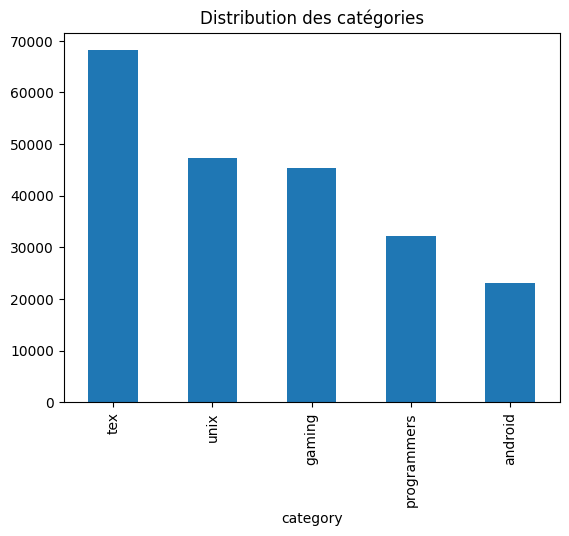

In [ ]:
#distribution of categoru
docs_df["category"].value_counts().plot(kind="bar")
plt.title("Distribution des catégories")
plt.show()

**Tag Statistics:**

Total unique tags (8,449), top 10 most frequent tags, and descriptive statistics of tags per document (Boxplot).

In [ ]:
tags_counts = dict()
for tags in docs_df["tags"]:
 for tag in tags:
  tags_counts[tag] = tags_counts.get(tag, 0) + 1
print(tags_counts.__len__(), "unique tag")
print("Most Frequent Tag :")
Counter(tags_counts).most_common(10)
docs_df["Tag#"] = docs_df["tags"].apply(lambda x: len(x))
docs_df["Tag#"].describe()

8449 unique tag
Most Frequent Tag :


,Tag#
count,216041.000000
mean,2.257215
std,1.140581
min,1.000000
25%,1.000000
50%,2.000000
75%,3.000000
max,5.000000


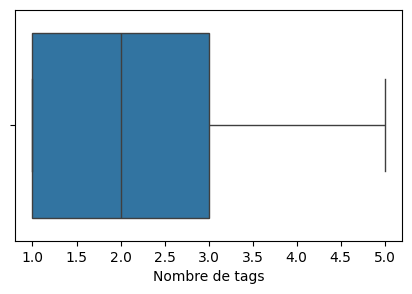

In [ ]:
plt.figure(figsize=(5, 3))
sns.boxplot(x=docs_df["Tag#"])
plt.xlabel("Nombre de tags")
plt.show()

**Data Integrity**:
* Missing Values Count of NAs
* identification of blank strings (e.g., the document with ID 34477 has a blank text field).

In [ ]:
# Count missing values per column
na_counts = docs_df.isna().sum()

# Compute percentage of missing values
na_pct = (na_counts / len(docs_df) * 100).round(2)

# Create a summary table
missing_summary = pd.DataFrame({
    "missing_count": na_counts,
    "missing_pct": na_pct
})

# Sort columns by number of missing values (descending)
missing_summary.sort_values("missing_count", ascending=False)

,missing_count,missing_pct
id,0,0.0
text,0,0.0
title,0,0.0
tags,0,0.0
category,0,0.0
Tag#,0,0.0


In [ ]:
# --- Small preprocessing step for clean data exploration ---

import re

# Check if a string is empty (after stripping spaces)
def is_blank_str(x):
    return isinstance(x, str) and x.strip() == ""

# Check if text is too short or contains only special characters
def is_quasi_empty_text(x, min_chars=5):
    if not isinstance(x, str):
        return False

    cleaned = x.strip()

    # Text is considered quasi-empty if very short
    if len(cleaned) < min_chars:
        return True

    # Or if it contains only non-alphanumeric characters
    if re.match(r'^\W+$', cleaned):
        return True

    return False

# Validate tags (must be a non-empty list of non-empty strings)
def is_bad_tags(x):
    if not isinstance(x, list):
        return True
    if len(x) == 0:
        return True

    # Clean tags
    cleaned_tags = [t.strip() for t in x if isinstance(t, str)]
    cleaned_tags = [t for t in cleaned_tags if t != ""]

    return len(cleaned_tags) == 0

# Check if text field has invalid type
def is_bad_type_text(x):
    return not isinstance(x, str)


# --- Basic data quality checks on documents ---

blank_title = docs_df["title"].apply(is_blank_str).sum()
blank_text  = docs_df["text"].apply(is_blank_str).sum()

quasi_empty_text = docs_df["text"].apply(is_quasi_empty_text).sum()

empty_or_bad_tags = docs_df["tags"].apply(is_bad_tags).sum()

bad_type_text = docs_df["text"].apply(is_bad_type_text).sum()

empty_categories = docs_df["category"].apply(is_blank_str).sum()

# Display exploration results
print("Blank title:", blank_title)
print("Blank text :", blank_text)
print("Quasi-empty text (short/punct only):", quasi_empty_text)
print("Empty or bad tags:", empty_or_bad_tags)
print("Bad type in text:", bad_type_text)
print("Empty categories :", empty_categories)

Blank title: 0
Blank text : 1
Quasi-empty text (short/punct only): 1
Empty or bad tags: 0
Bad type in text: 0
Empty categories : 0


In [ ]:
blank_text_rows = docs_df[docs_df["text"].apply(is_blank_str)]
print("Blank text rows:")
display(blank_text_rows)

quasi_empty_text_rows = docs_df[docs_df["text"].apply(is_quasi_empty_text)]
print("\nQuasi-empty text rows (short/punct only):")
display(quasi_empty_text_rows)

Blank text rows:


,id,text,title,tags,category,Tag#
34477,12193f6f-c8a8-4d30-9917-5f32cc0c2a31_245,,"Where can I find the ""mutant donkey woman"" horse?",[red-dead-redemption],gaming,1



Quasi-empty text rows (short/punct only):


,id,text,title,tags,category,Tag#
34477,12193f6f-c8a8-4d30-9917-5f32cc0c2a31_245,,"Where can I find the ""mutant donkey woman"" horse?",[red-dead-redemption],gaming,1


In [ ]:
# Install the word2number library (convert written numbers to digits)
!pip install word2number

  Preparing metadata (setup.py) ... done
  Created wheel for word2number: filename=word2number-1.1-py3-none-any.whl size=5568 sha256=d317ba6597c0bafd9397da8b7864248eded45a6ca6177e9c7d6ef30376c87c91
  Stored in directory: /root/.cache/pip/wheels/5b/79/fb/d25928e599c7e11fe4e00d32048cd74933f34a74c633d2aea6
Successfully built word2number


**Data Preparation for Documents analysis**

For Text:
* Numerical Normalization: Conversion of numbers written in letters to their numerical values.

* Lowercasing: Conversion of all characters to lowercase.

*  Special Character Removal: Stripping out non-alphanumeric characters and symbols.


For Tags:
* Special Character Removal: Elimination of symbols and punctuation within the tags.

* Empty and Duplicate Removal: Deletion of empty tags and removal of redundant entries.

* Tag Sorting: Alphabetical sorting of tags to handle consistency (e.g., "margins, geometry" and "geometry, margins").

In [ ]:
import re
import pandas as pd
from word2number import w2n

# Convert written numbers (e.g., "twenty five") into digits
def replace_num(match):
    try:
        return str(w2n.word_to_num(match.group(0)))
    except:
        # Keep original text if conversion fails
        return match.group(0)

# Clean and normalize text
def clean_text(s):
    if pd.isna(s):
        return ""

    # Convert to lowercase
    s = str(s).lower()

    # Define number word patterns
    units = r"(?:one|two|three|four|five|six|seven|eight|nine|ten|eleven|twelve|thirteen|fourteen|fifteen|sixteen|seventeen|eighteen|nineteen)"
    tens = r"(?:twenty|thirty|forty|fifty|sixty|seventy|eighty|ninety)"
    scales = r"(?:hundred|thousand|million|billion)"

    num_pattern = rf"\b(?:{units}|{tens}|{scales})(?:[\s\-]|and|{units}|{tens}|{scales})*\b"

    # Replace number words with digits
    s = re.sub(num_pattern, replace_num, s, flags=re.IGNORECASE)

    # Remove special characters (keep letters and digits only)
    s = re.sub(r"[^a-z0-9]", " ", s)

    # Normalize whitespace
    s = re.sub(r"\s+", " ", s).strip()

    return s

# Clean and normalize a list of tags
def clean_tags(tags):
    if not isinstance(tags, list):
        return ""

    cleaned = [clean_text(t) for t in tags]  # Clean each tag
    cleaned = [t for t in cleaned if t != ""]  # Remove empty tags
    cleaned = sorted(set(cleaned))  # Remove duplicates and sort

    return " ".join(cleaned)  # Return as a single string

In [ ]:
# Apply text cleaning to document titles
docs_df["title_clean"] = docs_df["title"].apply(clean_text)

# Apply text cleaning to document main text
docs_df["text_clean"] = docs_df["text"].apply(clean_text)

# Apply tag cleaning to document tags
docs_df["tags_clean"] = docs_df["tags"].apply(clean_tags)

In [ ]:
#merging Title, Text, and Tags into  Content_key

#Increasing title importance by tripling its frequency: docs_df["title_clean"]+ " ")*3

docs_df["content_key"] = (
    (docs_df["title_clean"]+ " ")*3 +
    docs_df["text_clean"]  + " " +
    docs_df["tags_clean"]
).str.strip()